# Aula 27 — Árvores de decisão — algoritmos clássicos de construção

**ECAA08 — Arquitetura de Sistemas SCADA | Grupo 06**  
**Integrantes:** Arthur, Caique, Luis Felipe e Marina  
**Planta:** Sistema SCADA aplicado a um Drone Agrícola de Pulverização  
**Etapa 3:** Árvores — planejamento e execução supervisionada de missões de pulverização


## 1. Contexto e objetivo no SCADA

O servidor SCADA pode oferecer uma hipótese de classificação operacional ao operador, com base em pressão, vazão, bateria e vento. As classes do experimento são normal, obstrução, vazão/pressão baixas, bateria baixa e vento alto. Os rótulos correspondem a cenários sintéticos injetados, não a diagnósticos confirmados em campo.

O classificador é consultivo: a HMI pode exibir sua sugestão ao lado dos alarmes determinísticos. Seu resultado não aciona a bomba, não elimina retenções e não autoriza retorno.

## 2. Modelo e fundamentação

Implementamos uma árvore binária gulosa para atributos contínuos com critérios Gini e entropia. Para proporções de classes $p_c$:

$$Gini=1-\sum_c p_c^2,\qquad H=-\sum_c p_c\log_2p_c.$$

Cada divisão candidata usa um atributo e o ponto médio entre valores distintos. Escolhemos a menor impureza ponderada dos filhos, respeitando profundidade e tamanho mínimo de folha. Essa é uma construção de estilo CART; trocar Gini por entropia não transforma a implementação em ID3 ou C4.5.

Também implementamos ID3 categórico, com ganho de informação e ramos por categoria. Atributos são discretizados por faixas de engenharia declaradas antes da separação dos dados. Categoria não vista retorna a classe majoritária do nó. C4.5 é discutido por sua razão de ganho e tratamento de atributos, mas não é implementado.

São 30 missões sintéticas com 20 amostras por missão. Treino, validação e teste são separados por missão, evitando colocar amostras da mesma missão nos dois lados. A árvore binária escolhe critério e profundidade pela validação; o teste é reservado até a escolha final.

## 3. Procedimento e demonstração

1. Gerar os cenários e registrar missão, atributos e classe.
2. Exibir os grupos de treino, validação e teste e verificar que são disjuntos.
3. Comparar seis combinações: Gini/entropia e profundidades 2, 3 e 4.
4. Mostrar matriz de confusão, acurácia e macro-F1 da configuração escolhida.
5. Executar o ID3 com discretização fixa e informar suas métricas separadamente.
6. Demonstrar que uma sugestão NORMAL não remove um bloqueio por vento.

Pergunta para a apresentação: alta acurácia sintética comprova diagnóstico real? Não. O resultado pode refletir apenas a separação definida no gerador.

## 4. Experimentos executáveis

Execute as células em ordem, com a pasta `Arquivos_de_Apoio` ao lado do notebook. Os algoritmos centrais aparecem abaixo; dados, funções comuns e verificações estão nos arquivos de apoio. Não há download de dados durante a execução.

In [1]:
from pathlib import Path
import sys
# Funciona na pasta da etapa, na raiz do repositório ou em uma subpasta da etapa.
origem = Path.cwd().resolve()
candidatos = [p / sufixo for p in [origem, *origem.parents]
              for sufixo in (Path('.'), Path('etapa-03-arvores'))]
ETAPA = next((p for p in candidatos if (p/'Arquivos_de_Apoio'/'scada_arvores.py').is_file()), None)
if ETAPA is None:
    raise FileNotFoundError('Extraia o pacote completo e abra o notebook na pasta etapa-03-arvores.')
sys.path.insert(0, str(ETAPA/'Arquivos_de_Apoio'))
from scada_arvores import *
import scada_arvores as core
import visualizacao as vis
from verificacoes import TESTES, conferir_rrt
import matplotlib.pyplot as plt
import json
print('Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica')


Sistema SCADA do Drone Agrícola | Grupo 06 | simulação acadêmica


In [2]:
def impureza(labels, criterio='gini'):
    if not labels: return 0.
    probs = [v/len(labels) for v in Counter(labels).values()]
    if criterio == 'gini': return 1-sum(p*p for p in probs)
    if criterio == 'entropy': return -sum(p*math.log2(p) for p in probs)
    raise ValueError('Critério desconhecido')


def treinar_arvore(X, y, criterio='gini', max_depth=4, min_leaf=5, profundidade=0):
    """Árvore binária gulosa para atributos contínuos; não implementa ID3/C4.5."""
    if not X or len(X) != len(y) or min_leaf < 1: raise ValueError('Amostra inválida')
    if any(len(x) != len(X[0]) or not all(math.isfinite(v) for v in x) for x in X):
        raise ValueError('Atributos inválidos')
    cont = Counter(y); classe = min(cont, key=lambda c: (-cont[c], c))
    no = dict(classe=classe, n=len(y), impureza=impureza(y, criterio))
    if profundidade >= max_depth or len(cont) == 1 or len(y) < 2*min_leaf: return no
    melhor = None
    for f in range(len(X[0])):
        valores = sorted(set(x[f] for x in X))
        for a, b in zip(valores, valores[1:]):
            limiar = (a+b)/2
            esquerda = [i for i, x in enumerate(X) if x[f] <= limiar]
            direita = [i for i, x in enumerate(X) if x[f] > limiar]
            if min(len(esquerda), len(direita)) < min_leaf: continue
            perda = sum(len(ix)*impureza([y[i] for i in ix], criterio) for ix in (esquerda, direita))/len(y)
            candidato = (perda, f, limiar, esquerda, direita)
            if melhor is None or candidato[:3] < melhor[:3]: melhor = candidato
    if melhor is None or no['impureza']-melhor[0] <= 1e-12: return no
    _, f, limiar, ie, idr = melhor
    no.update(feature=f, limiar=limiar)
    for lado, ix in [('esq', ie), ('dir', idr)]:
        no[lado] = treinar_arvore([X[i] for i in ix], [y[i] for i in ix], criterio,
                                 max_depth, min_leaf, profundidade+1)
    return no


In [3]:
def id3(X, y, atributos=None, max_depth=4):
    if not X or len(X)!=len(y): raise ValueError('Amostra inválida')
    atributos=list(range(len(X[0]))) if atributos is None else atributos
    freq=Counter(y); classe=min(freq,key=lambda c:(-freq[c],c))
    no={'classe':classe,'n':len(y)}
    if len(freq)==1 or not atributos or max_depth==0:return no
    escolhas=[]
    for f in atributos:
        partes={v:[i for i,x in enumerate(X) if x[f]==v] for v in sorted({x[f] for x in X})}
        ganho=impureza(y,'entropy')-sum(len(ix)*impureza([y[i] for i in ix],'entropy') for ix in partes.values())/len(y)
        escolhas.append((ganho,-f,partes))
    ganho,neg,partes=max(escolhas,key=lambda a:a[:2]); f=-neg
    if ganho<=1e-12:return no
    no['feature']=f; no['filhos']={}
    for valor,ix in partes.items():
        no['filhos'][valor]=id3([X[i] for i in ix],[y[i] for i in ix],
                               [a for a in atributos if a!=f],max_depth-1)
    return no


def prever_id3(no,x):
    while 'feature' in no:
        valor=x[no['feature']]
        if valor not in no['filhos']:return no['classe']
        no=no['filhos'][valor]
    return no['classe']


### Treino, seleção e teste por missão

Grupos: {'treino': [0, 1, 2, 3, 6, 7, 8, 9, 12, 13, 14, 15, 18, 19, 20, 21, 24, 25, 26, 27], 'validacao': [4, 10, 16, 22, 28], 'teste': [5, 11, 17, 23, 29]}
{'criterio': 'gini', 'profundidade': 2, 'macro_f1_validacao': 0.5}
{'criterio': 'gini', 'profundidade': 3, 'macro_f1_validacao': 0.7333333333333333}
{'criterio': 'gini', 'profundidade': 4, 'macro_f1_validacao': 0.9899937460913071}
{'criterio': 'entropy', 'profundidade': 2, 'macro_f1_validacao': 0.7215106732348111}
{'criterio': 'entropy', 'profundidade': 3, 'macro_f1_validacao': 0.9802197802197803}
{'criterio': 'entropy', 'profundidade': 4, 'macro_f1_validacao': 0.9802197802197803}
Escolhido: {'criterio': 'gini', 'profundidade': 4}
Teste: {'acuracia': 1.0, 'macro_f1': 1.0, 'confusao': [[20, 0, 0, 0, 0], [0, 20, 0, 0, 0], [0, 0, 20, 0, 0], [0, 0, 0, 20, 0], [0, 0, 0, 0, 20]]}


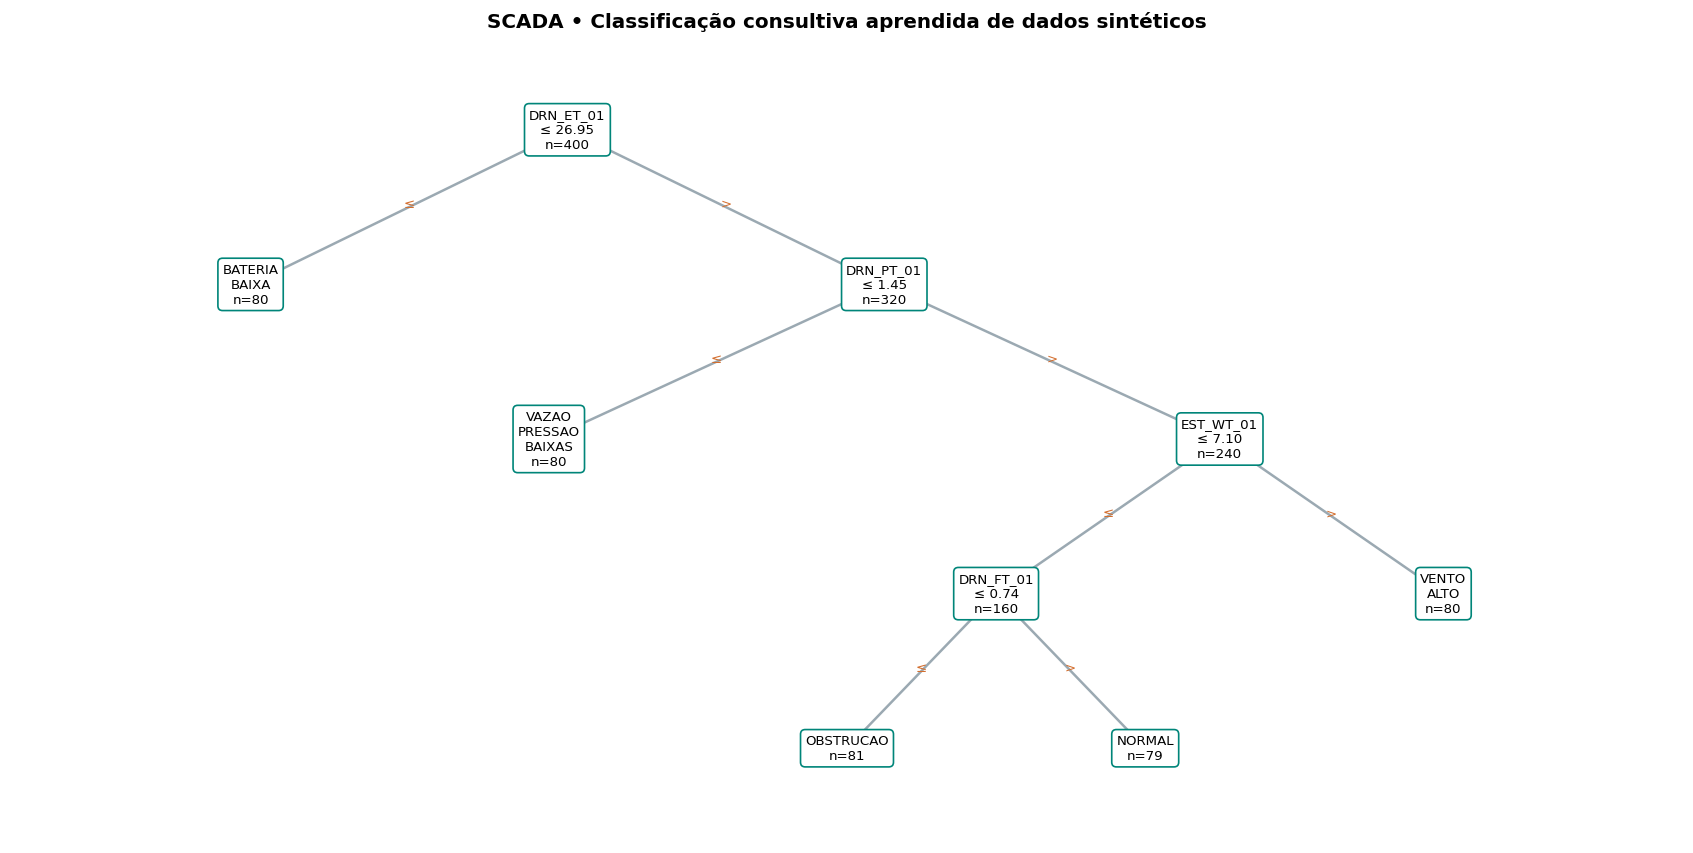

In [4]:
exp=experimento_classificacao()
print('Grupos:',exp['grupos'])
for item in exp['grid']:print(item)
print('Escolhido:',exp['escolhido'])
print('Teste:',exp['teste'])
vis.figura27(exp);plt.show()

### ID3 categórico e barreira supervisória

In [5]:
treino=[d for d in exp['dados'] if d['missao'] in exp['grupos']['treino']]
teste=[d for d in exp['dados'] if d['missao'] in exp['grupos']['teste']]
cat=id3([categorizar(d['x']) for d in treino],[d['y'] for d in treino])
print('ID3 com faixas fixas:',metricas([d['y'] for d in teste],[prever_id3(cat,categorizar(d['x'])) for d in teste]))
bb=dict(aprovada=True,rota_ok=True,na_faixa=True,sugestao_ml='NORMAL')
r=tick_supervisor(bb,telemetria(EST_WT_01=9))
assert not r['bomba']
print('Sugestão NORMAL não supera o bloqueio:',r['acao'],r['alarmes'])

ID3 com faixas fixas: {'acuracia': 0.87, 'macro_f1': 0.8739798622151562, 'confusao': [[20, 0, 0, 0, 0], [0, 20, 0, 0, 0], [3, 2, 15, 0, 0], [5, 0, 0, 15, 0], [3, 0, 0, 0, 17]]}
Sugestão NORMAL não supera o bloqueio: PAUSAR ['VENTO_ALTO']


### Verificação e resultados de referência

As verificações confrontam propriedades, referências independentes e casos de fronteira. Consulte `Arquivos_de_Apoio/verificacoes.py` para os critérios completos.

In [6]:
RESUMO = TESTES[27]()
print(json.dumps(RESUMO, ensure_ascii=False, indent=2))
print('Verificações da aula 27: APROVADAS')

{
  "escolhido": {
    "criterio": "gini",
    "profundidade": 4
  },
  "acuracia": 1.0,
  "macro_f1": 1.0,
  "confusao": [
    [
      20,
      0,
      0,
      0,
      0
    ],
    [
      0,
      20,
      0,
      0,
      0
    ],
    [
      0,
      0,
      20,
      0,
      0
    ],
    [
      0,
      0,
      0,
      20,
      0
    ],
    [
      0,
      0,
      0,
      0,
      20
    ]
  ]
}
Verificações da aula 27: APROVADAS


## 5. Interpretação, limites e continuidade

O gerador é propositalmente pequeno e controlado. Não contém diversidade agronômica, calibração de sensores, falhas simultâneas completas ou mudança de domínio. O conjunto de teste é independente por missão, mas provém do mesmo gerador. Uma acurácia elevada não estabelece segurança, causalidade ou desempenho em campo.

A classe vazão/pressão baixas representa uma hipótese ambígua; não localiza vazamento nem distingue toda falha de bomba. Dados não finitos impedem sugestão. A profundidade limitada e o mínimo de amostras por folha são pré-poda; não implementamos poda por custo-complexidade. Na Aula 28, o modelo treinado é usado somente para preencher a coluna de sugestão da HMI.

## 6. Referências

- [Scikit-learn — Decision Trees](https://sklearn.org/stable/modules/tree.html), critérios, divisões e diferenças entre algoritmos.
- [Quinlan — Induction of Decision Trees](https://doi.org/10.1007/BF00116251), ID3. Implementações próprias nesta entrega.